# Kappa Foundation – Group Assignment (decision date 31 Dec 2022)
Runs **offline** from `data/raw/` (download once with `python src/download_data.py`).
Every table -> `outputs/<TAG>/Txx_*.csv`, every figure -> `outputs/<TAG>/Fxx_*.png`.
For the 23 Oct revised mandate: change `TAG` and the parameters in the next cell, re-run, compare with `outputs/original/`.

In [1]:
import json
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import statsmodels.api as sm
from scipy.optimize import brentq, minimize, linprog
from scipy.stats import norm
from IPython.display import display

cwd = Path.cwd()
ROOT = next(
    (candidate for base in (cwd, *cwd.parents) for candidate in (base, base / "kappa")
     if (candidate / "config.json").is_file() and (candidate / "data" / "raw").is_dir()),
    None,
)
if ROOT is None:
    raise FileNotFoundError("Could not find config.json and data/raw from the notebook working directory")
RAW = ROOT / "data" / "raw"
with (ROOT / "config.json").open(encoding="utf-8") as f:
    cfg = json.load(f)
STOCKS, ETFS = cfg["stocks"], cfg["etfs"]; ASSETS = STOCKS + ETFS

# ---------------- ALL ASSUMPTIONS (freeze these on 22 Oct) ----------------
P = dict(
    TAG="original",
    FUND=12_000_000, PAY={2: 2_400_000, 5: 3_600_000},      # year -> USD (2024, 2027)
    GOAL_REAL=8_000_000, GOAL_YEARS=8,                       # Dec-2022 purchasing power, at 31 Dec 2030
    INFLATION=0.025,                                         # base CPI assumption (scenarios 2-4% below)
    ERP=0.05,                                                # forward-looking US equity risk premium
    RISK_AVERSION=4,                                         # A in U = mu - 0.5*A*var
    LOSS_LIMIT=0.15,                                         # 1-yr 95% loss diagnostic threshold, as % of TOTAL fund (our interpretation)
    CASH_BUFFER=250_000,                                     # liquidity / trading-cost reserve, earns 0%
    MAX_W=0.25,                                              # per-security cap in growth sleeve
    TC=0.001,                                                # 10 bp one-way on stocks/ETFs
    WIN=("2015-01", "2022-12"),                              # estimation window (96 months)
    EVAL=("2023-01", "2025-12"),                             # evaluation window, never used for decisions
    BENCH="SPY", FACTOR_STOCKS=["AAPL", "XOM"],
)
OUT = ROOT/"outputs"/P["TAG"]; OUT.mkdir(parents=True, exist_ok=True)
def save_table(df, name):
    df.to_csv(OUT/f"{name}.csv"); display(df.round(4)); return df
def save_fig(name):
    plt.tight_layout(); plt.savefig(OUT/f"{name}.png", dpi=150); plt.show()

## 1. Data: load raw files, build monthly returns, make dataset differences visible
Total return = month-end *Adj Close* (dividends reinvested) from the raw daily Yahoo files; price-only return from *Close* is shown alongside.
Factor data: Kenneth French **5 factors (Mkt-RF, SMB, HML, RMW, CMA, RF; file F-F_Research_Data_5_Factors_2x3)**, monthly, source percentages converted to decimals, `-99.99` = missing. FF3 uses Mkt-RF, SMB, HML; FF5 adds RMW and CMA. Month t return is aligned with factor month t.

In [2]:
import zipfile

def load_px(t):
    d = pd.read_csv(RAW/"yahoo"/f"{t}.csv", index_col=0)
    d.index = pd.to_datetime(d.index, utc=True).tz_convert(None).normalize()
    if d.index.has_duplicates or not d.index.is_monotonic_increasing:
        raise ValueError(f"{t}: daily prices contain duplicate or unsorted dates")
    required = ["Adj Close", "Close"]
    if not set(required).issubset(d.columns) or d[required].isna().any().any():
        raise ValueError(f"{t}: missing required adjusted/close prices")
    return d

raw = {t: load_px(t) for t in ASSETS}
def month_end(px): return px.groupby(px.index.to_period("M")).last()
ret_tr = month_end(pd.DataFrame({t: raw[t]["Adj Close"] for t in ASSETS})).pct_change().iloc[1:]
ret_pr = month_end(pd.DataFrame({t: raw[t]["Close"] for t in ASSETS})).pct_change().iloc[1:]

if ret_tr.index.has_duplicates or not ret_tr.index.is_monotonic_increasing:
    raise ValueError("Monthly return index contains duplicate or unsorted months")
if not np.isfinite(ret_tr.to_numpy()).all() or (ret_tr.abs() >= 1).any().any():
    raise ValueError("Monthly total returns must be finite decimal returns, not percentages")

def read_french(zipname, names):
    with zipfile.ZipFile(RAW/"french"/zipname) as z:
        csv_names = [name for name in z.namelist() if name.lower().endswith(".csv")]
        if len(csv_names) != 1:
            raise ValueError(f"{zipname}: expected one CSV member, found {csv_names}")
        lines = z.read(csv_names[0]).decode("latin-1").splitlines()
    rows, started = [], False
    for line in lines:
        p = [x.strip() for x in line.split(",")]
        if len(p[0]) == 6 and p[0].isdigit():
            started = True
            rows.append(p[:len(names)+1])
        elif started:
            break
    if not rows:
        raise ValueError(f"{zipname}: no monthly observations found")
    df = pd.DataFrame(rows, columns=["date"]+names)
    df.index = pd.PeriodIndex(pd.to_datetime(df.pop("date"), format="%Y%m"), freq="M")
    if df.index.has_duplicates or not df.index.is_monotonic_increasing:
        raise ValueError(f"{zipname}: duplicate or unsorted monthly factor dates")
    return df.astype(float).replace([-99.99, -999.0], np.nan) / 100

FF3 = ["Mkt-RF", "SMB", "HML"]
FF5 = FF3 + ["RMW", "CMA"]
FACTOR_COLUMNS = FF5 + ["RF"]
fac = read_french("F-F_Research_Data_5_Factors_2x3_CSV.zip", FACTOR_COLUMNS)
if not set(FACTOR_COLUMNS).issubset(fac.columns):
    raise ValueError(f"Required factor columns are missing: {set(FACTOR_COLUMNS) - set(fac.columns)}")
if fac.index.has_duplicates or not fac.index.is_monotonic_increasing:
    raise ValueError("Factor table contains duplicate or unsorted months")
if not np.isfinite(fac.to_numpy()).all():
    raise ValueError("Required monthly factor series contain missing/non-finite values")
if fac[FACTOR_COLUMNS].abs().to_numpy().max() >= 1 or fac["RF"].abs().max() >= 0.05:
    raise ValueError("Factor values are inconsistent with decimal monthly units")

W0, W1 = P["WIN"]
E0, E1 = P["EVAL"]
if (W0, W1) != ("2015-01", "2022-12"):
    raise ValueError("Estimation window violates the frozen assignment policy")
if (E0, E1) != ("2023-01", "2025-12"):
    raise ValueError("Evaluation window violates the frozen assignment policy")
policy_path = OUT/"frozen_policy.json"
if policy_path.exists():
    saved_policy = json.loads(policy_path.read_text(encoding="utf-8"))
    if tuple(saved_policy.get("estimation_window", ())) != (W0, W1):
        raise ValueError("Configured estimation period differs from saved frozen policy")
    if tuple(saved_policy.get("evaluation_window", ())) != (E0, E1):
        raise ValueError("Configured evaluation period differs from saved frozen policy")

expected_train = pd.period_range(W0, W1, freq="M")
Rw = ret_tr.loc[W0:W1]
Fw = fac.loc[W0:W1]
if not Rw.index.equals(Fw.index):
    raise ValueError("Asset returns and factor months are not exactly aligned")
if not Rw.index.equals(expected_train) or not Fw.index.equals(expected_train):
    raise ValueError("Estimation observations do not exactly match frozen monthly dates")
if len(Rw) != 96 or len(Rw) < 60:
    raise ValueError(f"Frozen estimation sample must contain 96 monthly observations; found {len(Rw)}")
if not np.isfinite(Rw.to_numpy()).all() or not np.isfinite(Fw[FACTOR_COLUMNS].to_numpy()).all():
    raise ValueError("Missing/non-finite return or factor observations in estimation window")

ex = Rw.sub(Fw["RF"], axis=0)
ann_geo = lambda r: (1+r).prod()**(12/len(r)) - 1
dq = pd.DataFrame({"first_price_date": [raw[t].index[0].date() for t in ASSETS],
                   "months_in_window": Rw.count().values,
                   "ann_return_total": [ann_geo(Rw[t]) for t in ASSETS],
                   "ann_return_price_only": [ann_geo(ret_pr.loc[W0:W1, t]) for t in ASSETS]}, index=ASSETS)
save_table(dq, "T01_data_quality")
print("Window:", Rw.index[0], "to", Rw.index[-1], "| n =", len(Rw), "| factors through:", fac.index[-1])

,first_price_date,months_in_window,ann_return_total,ann_return_price_only
AAPL,2014-12-01,96,0.2298,0.2137
MSFT,2014-12-01,96,0.2488,0.2278
JPM,2014-12-01,96,0.1311,0.1000
JNJ,2014-12-01,96,0.0968,0.0677
UNH,2014-12-01,96,0.2490,0.2302
XOM,2014-12-01,96,0.0705,0.0223
PG,2014-12-01,96,0.0970,0.0657
HD,2014-12-01,96,0.1740,0.1476
NEE,2014-12-01,96,0.1831,0.1540
CAT,2014-12-01,96,0.1608,0.1278


Window: 2015-01 to 2022-12 | n = 96 | factors through: 2026-08


In [3]:
import hashlib
rec = json.load(open(RAW/"source_record.json"))
chk = pd.DataFrame(rec["entries"])[["source","id","file","sha256"]]
chk["sha_ok"] = [hashlib.sha256((ROOT/f).read_bytes()).hexdigest() == h for f, h in zip(chk.file, chk.sha256)]
if not chk["sha_ok"].all():
    raise ValueError("Raw source hash verification failed; inspect T00_source_record before analysis")
print("Retrieved (UTC):", rec["retrieval_utc"], "| yfinance", rec["yfinance"], "| pandas", rec["pandas"], "| failed downloads:", rec["failures"] or "none")
save_table(chk.set_index("id"), "T00_source_record")

Retrieved (UTC): 2026-10-20T10:51:08.923437Z | yfinance 1.7.0 | pandas 3.0.6 | failed downloads: none


,source,file,sha256,sha_ok
id,,,,
AAPL,Yahoo Finance via yfinance,data\raw\yahoo\AAPL.csv,fefa910b8ef47a0289a7d10e4a2c71ca9c4e45f7fd94c0...,True
MSFT,Yahoo Finance via yfinance,data\raw\yahoo\MSFT.csv,133eeff6b9c39894220b065c240f3289714fe191e877bb...,True
JPM,Yahoo Finance via yfinance,data\raw\yahoo\JPM.csv,6e7aa48feb0b0c1af5770341694372b8700a84b2b5fc60...,True
JNJ,Yahoo Finance via yfinance,data\raw\yahoo\JNJ.csv,0de9b3bf48972a21907babd0249ce8796bd446ddd09f43...,True
UNH,Yahoo Finance via yfinance,data\raw\yahoo\UNH.csv,22642499d5ab8d532f7b2929b821706a223ceeafa1c122...,True
XOM,Yahoo Finance via yfinance,data\raw\yahoo\XOM.csv,2130d65d8dacd582f80f310c70d90bdcaf256de0f3b41b...,True
PG,Yahoo Finance via yfinance,data\raw\yahoo\PG.csv,3bc487115a8735d13534f7bf5725a40331cabb1da929e9...,True
HD,Yahoo Finance via yfinance,data\raw\yahoo\HD.csv,1d3e76b3cfbf6a04a05463d466b9ad5b3e5a2f3cfceba6...,True
NEE,Yahoo Finance via yfinance,data\raw\yahoo\NEE.csv,cd72ac0806761ce7577d75f9f0892f399275a0c984f530...,True


,source,file,sha256,sha_ok
id,,,,
AAPL,Yahoo Finance via yfinance,data\raw\yahoo\AAPL.csv,fefa910b8ef47a0289a7d10e4a2c71ca9c4e45f7fd94c0...,True
MSFT,Yahoo Finance via yfinance,data\raw\yahoo\MSFT.csv,133eeff6b9c39894220b065c240f3289714fe191e877bb...,True
JPM,Yahoo Finance via yfinance,data\raw\yahoo\JPM.csv,6e7aa48feb0b0c1af5770341694372b8700a84b2b5fc60...,True
JNJ,Yahoo Finance via yfinance,data\raw\yahoo\JNJ.csv,0de9b3bf48972a21907babd0249ce8796bd446ddd09f43...,True
UNH,Yahoo Finance via yfinance,data\raw\yahoo\UNH.csv,22642499d5ab8d532f7b2929b821706a223ceeafa1c122...,True
XOM,Yahoo Finance via yfinance,data\raw\yahoo\XOM.csv,2130d65d8dacd582f80f310c70d90bdcaf256de0f3b41b...,True
PG,Yahoo Finance via yfinance,data\raw\yahoo\PG.csv,3bc487115a8735d13534f7bf5725a40331cabb1da929e9...,True
HD,Yahoo Finance via yfinance,data\raw\yahoo\HD.csv,1d3e76b3cfbf6a04a05463d466b9ad5b3e5a2f3cfceba6...,True
NEE,Yahoo Finance via yfinance,data\raw\yahoo\NEE.csv,cd72ac0806761ce7577d75f9f0892f399275a0c984f530...,True


**Candidate universe (edit roles/sectors/evidence).** 10 US large caps in 8 sectors + SPY (cap-weighted US market, also the benchmark) and USMV (minimum-volatility mandate).
All 10 stocks appear in the archived constituent list at revision 1130173030 (28 Dec 2022); verify there were no membership changes through 31 Dec. Yahoo price history establishes trading coverage, not index membership.
Selection-bias caveat: names were chosen with knowledge that they survived; we deliberately avoided obvious later winners/losers rules, but the bias cannot be removed.

In [4]:
roles = {"AAPL":("Info Tech","mega-cap growth"),"MSFT":("Info Tech","mega-cap growth/quality"),"JPM":("Financials","rate/credit-cycle cyclical"),
         "JNJ":("Health Care","defensive"),"UNH":("Health Care","defensive growth"),"XOM":("Energy","commodity/inflation hedge"),
         "PG":("Staples","defensive"),"HD":("Cons. Disc.","cyclical consumer"),"NEE":("Utilities","bond-like/rate sensitive"),
         "CAT":("Industrials","cyclical value"),"SPY":("Broad ETF","cap-weighted US market / benchmark"),"USMV":("Broad ETF","minimum-volatility mandate")}
uni = pd.DataFrame(roles, index=["sector","role"]).T
stock_tickers = STOCKS
etf_tickers = ETFS
uni["eligibility_evidence"] = "Stock appears in archived S&P 500 constituent snapshot dated 2022-12-28; membership through 2022-12-31 not independently verified"
uni["eligibility_source"] = "https://en.wikipedia.org/w/index.php?title=List_of_S%26P_500_companies&oldid=1130173030"
uni.loc[etf_tickers, "eligibility_evidence"] = "ETF candidate; not an S&P 500 constituent. Case-date exchange/listing and mandate documentation not present in this project."
uni.loc[etf_tickers, "eligibility_source"] = "Not documented in the saved case-date source record"
uni["trading_coverage"] = "Yahoo daily prices available over 2015-2022; see T01 and source record"
save_table(uni, "T02_universe")

,sector,role,eligibility_evidence,eligibility_source,trading_coverage
AAPL,Info Tech,mega-cap growth,Stock appears in archived S&P 500 constituent ...,https://en.wikipedia.org/w/index.php?title=Lis...,Yahoo daily prices available over 2015-2022; s...
MSFT,Info Tech,mega-cap growth/quality,Stock appears in archived S&P 500 constituent ...,https://en.wikipedia.org/w/index.php?title=Lis...,Yahoo daily prices available over 2015-2022; s...
JPM,Financials,rate/credit-cycle cyclical,Stock appears in archived S&P 500 constituent ...,https://en.wikipedia.org/w/index.php?title=Lis...,Yahoo daily prices available over 2015-2022; s...
JNJ,Health Care,defensive,Stock appears in archived S&P 500 constituent ...,https://en.wikipedia.org/w/index.php?title=Lis...,Yahoo daily prices available over 2015-2022; s...
UNH,Health Care,defensive growth,Stock appears in archived S&P 500 constituent ...,https://en.wikipedia.org/w/index.php?title=Lis...,Yahoo daily prices available over 2015-2022; s...
XOM,Energy,commodity/inflation hedge,Stock appears in archived S&P 500 constituent ...,https://en.wikipedia.org/w/index.php?title=Lis...,Yahoo daily prices available over 2015-2022; s...
PG,Staples,defensive,Stock appears in archived S&P 500 constituent ...,https://en.wikipedia.org/w/index.php?title=Lis...,Yahoo daily prices available over 2015-2022; s...
HD,Cons. Disc.,cyclical consumer,Stock appears in archived S&P 500 constituent ...,https://en.wikipedia.org/w/index.php?title=Lis...,Yahoo daily prices available over 2015-2022; s...
NEE,Utilities,bond-like/rate sensitive,Stock appears in archived S&P 500 constituent ...,https://en.wikipedia.org/w/index.php?title=Lis...,Yahoo daily prices available over 2015-2022; s...
CAT,Industrials,cyclical value,Stock appears in archived S&P 500 constituent ...,https://en.wikipedia.org/w/index.php?title=Lis...,Yahoo daily prices available over 2015-2022; s...


,sector,role,eligibility_evidence,eligibility_source,trading_coverage
AAPL,Info Tech,mega-cap growth,Stock appears in archived S&P 500 constituent ...,https://en.wikipedia.org/w/index.php?title=Lis...,Yahoo daily prices available over 2015-2022; s...
MSFT,Info Tech,mega-cap growth/quality,Stock appears in archived S&P 500 constituent ...,https://en.wikipedia.org/w/index.php?title=Lis...,Yahoo daily prices available over 2015-2022; s...
JPM,Financials,rate/credit-cycle cyclical,Stock appears in archived S&P 500 constituent ...,https://en.wikipedia.org/w/index.php?title=Lis...,Yahoo daily prices available over 2015-2022; s...
JNJ,Health Care,defensive,Stock appears in archived S&P 500 constituent ...,https://en.wikipedia.org/w/index.php?title=Lis...,Yahoo daily prices available over 2015-2022; s...
UNH,Health Care,defensive growth,Stock appears in archived S&P 500 constituent ...,https://en.wikipedia.org/w/index.php?title=Lis...,Yahoo daily prices available over 2015-2022; s...
XOM,Energy,commodity/inflation hedge,Stock appears in archived S&P 500 constituent ...,https://en.wikipedia.org/w/index.php?title=Lis...,Yahoo daily prices available over 2015-2022; s...
PG,Staples,defensive,Stock appears in archived S&P 500 constituent ...,https://en.wikipedia.org/w/index.php?title=Lis...,Yahoo daily prices available over 2015-2022; s...
HD,Cons. Disc.,cyclical consumer,Stock appears in archived S&P 500 constituent ...,https://en.wikipedia.org/w/index.php?title=Lis...,Yahoo daily prices available over 2015-2022; s...
NEE,Utilities,bond-like/rate sensitive,Stock appears in archived S&P 500 constituent ...,https://en.wikipedia.org/w/index.php?title=Lis...,Yahoo daily prices available over 2015-2022; s...
CAT,Industrials,cyclical value,Stock appears in archived S&P 500 constituent ...,https://en.wikipedia.org/w/index.php?title=Lis...,Yahoo daily prices available over 2015-2022; s...


## 2. Bonds: valuation, yields, incomplete term structure, duration/convexity, funding
**Term-structure treatment:** zeros give spot 1y and 2y directly. Spots at 3y, 5y, 8y are bootstrapped from the coupon bonds, with **linear interpolation of spot rates** between quoted maturities (4y, 6y, 7y are not observed). This is an assumption; its effect is only on Delta and Epsilon.
**Shocks:** parallel ±100bp (a normal year's move) and +250bp (roughly the size of 2022's rise, information available at the cutoff); steepener/flattener = −50bp at 1y rising linearly to +50bp at 8y (and reverse).

In [5]:
bonds = pd.DataFrame({"mat":[1,2,3,5,8], "cpn":[0,0,4,3.5,4.5], "price":[958.77,922.78,1002.49,986.07,1040.71]},
                     index=["Alpha","Beta","Gamma","Delta","Epsilon"])
def cfs(b):
    t = np.arange(1, int(b["mat"])+1); c = np.full(len(t), b["cpn"]*10.0); c[-1] += 1000; return t, c
def price_ytm(b, y): t, c = cfs(b); return (c/(1+y)**t).sum()
def ytm(b): return brentq(lambda y: price_ytm(b, y)-b["price"], -0.05, 0.5)

# bootstrap spot curve with linear interpolation between knots
spots = {}
for n, b in bonds.iterrows():
    T = int(b["mat"]); t, c = cfs(b); known = sorted(spots)
    def f(s):
        curve_t = np.interp(t, known+[T], [spots[k] for k in known]+[s])
        return (c/(1+curve_t)**t).sum() - b["price"]
    spots[T] = brentq(f, -0.05, 0.5)
yrs = np.arange(1, 9); spot_v = np.interp(yrs, list(spots), list(spots.values()))
curve = lambda t: np.interp(t, yrs, spot_v)
fwd = [spot_v[0]] + [((1+spot_v[i])**(i+1)/(1+spot_v[i-1])**i - 1) for i in range(1, 8)]
save_table(pd.DataFrame({"spot":spot_v, "implied_forward":fwd, "observed": [y in spots for y in yrs]}, index=yrs), "T03_spot_curve")

rows = []
for n, b in bonds.iterrows():
    y = ytm(b); t, c = cfs(b); pv = c/(1+y)**t; p0 = b["price"]
    mac = (t*pv).sum()/p0; mod = mac/(1+y); cx = (t*(t+1)*c/(1+y)**(t+2)).sum()/p0
    d = 1e-4; up, dn = price_ytm(b, y+d), price_ytm(b, y-d)
    rows.append(dict(bond=n, maturity=b["mat"], coupon_pct=b["cpn"], price=p0, ytm=y, current_yield=b["cpn"]*10/p0,
                     spot_at_maturity=spots[int(b["mat"])], macaulay=mac, modified=mod, convexity=cx,
                     mod_dur_numeric=-(up-dn)/(2*p0*d), convexity_numeric=(up+dn-2*p0)/(p0*d*d)))
bt = save_table(pd.DataFrame(rows).set_index("bond"), "T04_bond_analytics")

# duration/convexity approximation vs exact repricing
rows = []
for n, b in bonds.iterrows():
    r = bt.loc[n]; t, c = cfs(b)
    for d in [0.01, -0.01, 0.025]:
        exact_y = price_ytm(b, r["ytm"]+d)/b["price"]-1
        exact_curve = (c/(1+curve(t)+d)**t).sum()/b["price"]-1
        dur = -r["modified"]*d; dc = dur + 0.5*r["convexity"]*d**2
        rows.append(dict(bond=n, shock_bp=d*1e4, duration_only=dur, duration_convexity=dc, exact_yield_reprice=exact_y,
                         exact_spot_curve_reprice=exact_curve, error_dur_conv=dc-exact_y))
save_table(pd.DataFrame(rows).set_index(["bond","shock_bp"]), "T05_duration_vs_exact")

,spot,implied_forward,observed
1,0.0430,0.0430,True
2,0.0410,0.0390,True
3,0.0390,0.0350,True
4,0.0385,0.0370,False
5,0.0380,0.0360,True
6,0.0383,0.0400,False
7,0.0387,0.0407,False
8,0.0390,0.0413,True


,maturity,coupon_pct,price,ytm,current_yield,spot_at_maturity,macaulay,modified,convexity,mod_dur_numeric,convexity_numeric
bond,,,,,,,,,,,
Alpha,1.0,0.0,958.77,0.0430,0.0000,0.043,1.0000,0.9588,1.8385,0.9588,1.8386
Beta,2.0,0.0,922.78,0.0410,0.0000,0.041,2.0000,1.9212,5.5367,1.9212,5.5367
Gamma,3.0,4.0,1002.49,0.0391,0.0399,0.039,2.8862,2.7776,10.5528,2.7776,10.5528
Delta,5.0,3.5,986.07,0.0381,0.0355,0.038,4.6704,4.4989,25.4023,4.4989,25.4023
Epsilon,8.0,4.5,1040.71,0.0390,0.0432,0.039,6.9182,6.6586,54.7855,6.6586,54.7855


duration_only  duration_convexity  exact_yield_reprice  \
bond    shock_bp                                                           
Alpha    100.0          -0.0096             -0.0095              -0.0095   
        -100.0           0.0096              0.0097               0.0097   
         250.0          -0.0240             -0.0234              -0.0234   
Beta     100.0          -0.0192             -0.0189              -0.0189   
        -100.0           0.0192              0.0195               0.0195   
         250.0          -0.0480             -0.0463              -0.0464   
Gamma    100.0          -0.0278             -0.0272              -0.0273   
        -100.0           0.0278              0.0283               0.0283   
         250.0          -0.0694             -0.0661              -0.0663   
Delta    100.0          -0.0450             -0.0437              -0.0437   
        -100.0           0.0450              0.0463               0.0463   
         250.0          -0.1125             -0.1045              -0.1050   
Epsilon  100.0          -0.0666             -0.0638              -0.0639   
        -100.0           0.0666              0.0693               0.0694   
         250.0          -0.1665             -0.1493              -0.1506   

                  exact_spot_curve_reprice  error_dur_conv  
bond    shock_bp                                            
Alpha    100.0                     -0.0095          0.0000  
        -100.0                      0.0097         -0.0000  
         250.0                     -0.0234          0.0000  
Beta     100.0                     -0.0189          0.0000  
        -100.0                      0.0195         -0.0000  
         250.0                     -0.0464          0.0001  
Gamma    100.0                     -0.0273          0.0000  
        -100.0                      0.0283         -0.0000  
         250.0                     -0.0663          0.0001  
Delta    100.0                     -0.0438          0.0000  
        -100.0                      0.0463         -0.0000  
         250.0                     -0.1050          0.0004  
Epsilon  100.0                     -0.0639          0.0001  
        -100.0                      0.0694         -0.0001  
         250.0                     -0.1506          0.0013

duration_only  duration_convexity  exact_yield_reprice  \
bond    shock_bp                                                           
Alpha    100.0        -0.009588           -0.009496            -0.009497   
        -100.0         0.009588            0.009680             0.009681   
         250.0        -0.023969           -0.023395            -0.023408   
Beta     100.0        -0.019212           -0.018935            -0.018939   
        -100.0         0.019212            0.019489             0.019493   
         250.0        -0.048031           -0.046301            -0.046354   
Gamma    100.0        -0.027776           -0.027249            -0.027257   
        -100.0         0.027776            0.028304             0.028312   
         250.0        -0.069441           -0.066143            -0.066270   
Delta    100.0        -0.044989           -0.043719            -0.043747   
        -100.0         0.044989            0.046260             0.046288   
         250.0        -0.112474           -0.104535            -0.104956   
Epsilon  100.0        -0.066586           -0.063847            -0.063930   
        -100.0         0.066586            0.069325             0.069413   
         250.0        -0.166465           -0.149345            -0.150600   

                  exact_spot_curve_reprice  error_dur_conv  
bond    shock_bp                                            
Alpha    100.0                   -0.009497    8.729694e-07  
        -100.0                    0.009681   -8.898719e-07  
         250.0                   -0.023408    1.344858e-05  
Beta     100.0                   -0.018939    3.503652e-06  
        -100.0                    0.019493   -3.588815e-06  
         250.0                   -0.046354    5.378573e-05  
Gamma    100.0                   -0.027261    8.288048e-06  
        -100.0                    0.028317   -8.529854e-06  
         250.0                   -0.066279    1.267962e-04  
Delta    100.0                   -0.043760    2.768382e-05  
        -100.0                    0.046302   -2.876361e-05  
         250.0                   -0.104986    4.206408e-04  
Epsilon  100.0                   -0.063939    8.343498e-05  
        -100.0                    0.069423   -8.789837e-05  
         250.0                   -0.150621    1.255344e-03

In [6]:
# ---- funding plan: cheapest set of bonds whose cash flows cover both payments, surplus cash earns 0% (conservative) ----
H = 5; names = ["Alpha","Beta","Gamma","Delta"]       # Epsilon excluded: only 5y of its cash flows usable without a resale-price assumption
cfm = np.zeros((len(names), H))
for i, n in enumerate(names): t, c = cfs(bonds.loc[n]); cfm[i, :len(t)] = c
pay = np.zeros(H)
for yr, a in P["PAY"].items(): pay[yr-1] = a
cum = np.tril(np.ones((H, H)))
res = linprog(c=bonds.loc[names, "price"].values, A_ub=-(cum@cfm.T), b_ub=-(cum@pay), bounds=[(0, None)]*len(names), method="highs")
if not res.success:
    raise RuntimeError(f"Bond cash-flow funding optimization failed: {res.message}")
units = np.ceil(res.x - 1e-9)                          # whole bonds, rounding up keeps feasibility
bond_cost = float((units*bonds.loc[names, "price"].values).sum())
inflow = cfm.T@units
bal = np.cumsum(inflow - pay); assert bal.min() > -1e-6
fund_tbl = pd.DataFrame({"bond_cash_in": inflow, "payment": pay, "closing_cash_0pct": bal}, index=range(2023, 2028))
save_table(fund_tbl, "T06_funding_cashflows")
hold = pd.DataFrame({"units": units, "price": bonds.loc[names, "price"].values}, index=names); hold["cost_usd"] = hold.units*hold.price
save_table(hold, "T07_bond_holdings")

shifts = {"base": lambda t: 0*t, "parallel +100bp": lambda t: 0.01+0*t, "parallel -100bp": lambda t: -0.01+0*t,
          "parallel +250bp": lambda t: 0.025+0*t,
          "steepener (-50bp 1y -> +50bp 8y)": lambda t: -0.005+0.01*(t-1)/7, "flattener (+50bp 1y -> -50bp 8y)": lambda t: 0.005-0.01*(t-1)/7}
def asset_pv(sh): return sum(units[i]*(lambda tc: (tc[1]/(1+curve(tc[0])+sh(tc[0]))**tc[0]).sum())(cfs(bonds.loc[n])) for i, n in enumerate(names))
def liab_pv(sh): return sum(pay[k]/(1+curve(k+1)+sh(k+1))**(k+1) for k in range(H) if pay[k] > 0)
rows = []
for k, sh in shifts.items():
    a, l = asset_pv(sh), liab_pv(sh); rows.append(dict(scenario=k, assets_pv=a, liabilities_pv=l, surplus=a-l))
sc = pd.DataFrame(rows).set_index("scenario"); sc["surplus_change"] = sc.surplus - sc.loc["base","surplus"]
save_table(sc, "T08_rate_scenarios_funding")
tt = np.array([k+1 for k in range(H) if pay[k] > 0]); w_l = np.array([pay[k-1]/(1+curve(k))**k for k in tt])
print("Liability PV (spot curve): %.0f | bond cost (0%% carry): %.0f | surplus cash end-2027: %.0f" % (liab_pv(shifts['base']), bond_cost, bal[-1]))
print("Liability Macaulay duration: %.2f yrs" % ((tt*w_l).sum()/w_l.sum()))
def mac_pv(n):
    t_, c_ = cfs(bonds.loc[n]); pv_ = c_/(1+curve(t_))**t_; return (t_*pv_).sum(), pv_.sum()
print("Matching-bond portfolio Macaulay duration: %.2f yrs" % (sum(units[i]*mac_pv(n)[0] for i, n in enumerate(names))/sum(units[i]*mac_pv(n)[1] for i, n in enumerate(names))))

,bond_cash_in,payment,closing_cash_0pct
2023,114030.0,0.0,114030.0
2024,2286030.0,2400000.0,60.0
2025,114030.0,0.0,114090.0
2026,114030.0,0.0,228120.0
2027,3372030.0,3600000.0,150.0


,units,price,cost_usd
Alpha,-0.0,958.77,-0.00
Beta,2172.0,922.78,2004278.16
Gamma,-0.0,1002.49,-0.00
Delta,3258.0,986.07,3212616.06


,assets_pv,liabilities_pv,surplus,surplus_change
scenario,,,,
base,5.216894e+06,5.202219e+06,14675.7065,0.0000
parallel +100bp,5.038352e+06,5.020434e+06,17917.8939,3242.1874
parallel -100bp,5.404715e+06,5.393552e+06,11163.2940,-3512.4125
parallel +250bp,4.786707e+06,4.764389e+06,22318.6307,7642.9242
steepener (-50bp 1y -> +50bp 8y),5.223263e+06,5.207235e+06,16028.3922,1352.6857
flattener (+50bp 1y -> -50bp 8y),5.210725e+06,5.197401e+06,13324.0480,-1351.6585


Liability PV (spot curve): 5202219 | bond cost (0% carry): 5216894 | surplus cash end-2027: 150
Liability Macaulay duration: 3.72 yrs
Matching-bond portfolio Macaulay duration: 3.65 yrs


## 3. Mandate: growth sleeve size, real goal, loss-tolerance interpretation
* Bonds are held to maturity and cash-flow matched, so the two payments are funded without relying on equity markets (default-free per the case).
* Real goal: remaining fund at 31 Dec 2030 ≥ 8m × (1+π)^8. π is not given; base 2.5% (long-run expectation, near market-implied break-evens and above the 2% target; **Dec-2022 realised inflation was much higher, so this is a judgement**), scenarios 2–4%.
* “Losses approaching 15%” interpreted as: **1-year 95% loss on the total fund ≤ 15%** (bonds held to maturity: loss comes from the growth sleeve only). Also reported: worst historical 12-month and max drawdown.

In [7]:
rf_ann = spots[1]                                       # 1y zero yield: observed risk-free rate at the decision date
G_total = P["FUND"] - bond_cost - P["CASH_BUFFER"]       # growth sleeve
tc_initial = P["TC"]*G_total
other = P["CASH_BUFFER"] - tc_initial + bal[-1]          # buffer net of costs + leftover bond cash, 0% to 2030
share = G_total/P["FUND"]
def need_growth(infl): return P["GOAL_REAL"]*(1+infl)**P["GOAL_YEARS"] - other
def req_ret(infl): return (need_growth(infl)/G_total)**(1/P["GOAL_YEARS"]) - 1
goal_tbl = pd.DataFrame({"inflation": [0.02,0.025,0.03,0.04]})
goal_tbl["nominal_goal_2030"] = P["GOAL_REAL"]*(1+goal_tbl.inflation)**P["GOAL_YEARS"]
goal_tbl["required_growth_return_pa"] = goal_tbl.inflation.map(req_ret)
save_table(goal_tbl.set_index("inflation"), "T09_goal_requirements")
print("Growth sleeve: %.0f (%.1f%% of fund) | risk-free (1y zero): %.2f%% | required growth return at base inflation: %.2f%%" %
      (G_total, share*100, rf_ann*100, req_ret(P["INFLATION"])*100))

,nominal_goal_2030,required_growth_return_pa
inflation,,
0.020,9.373275e+06,0.0427
0.025,9.747223e+06,0.0480
0.030,1.013416e+07,0.0532
0.040,1.094855e+07,0.0637


Growth sleeve: 6533106 (54.4% of fund) | risk-free (1y zero): 4.30% | required growth return at base inflation: 4.80%


## 4. Portfolio decision
Expected returns: **CAPM-anchored** (rf = 1y zero yield; μᵢ = rf + βᵢ·ERP with ERP = 5%). The ERP is a team-selected forward-looking assumption, not a return forecast supplied by the case; historical means are shown only in the rejected alternative because they are noisy estimation inputs.
Objective: max μ'w − ½A·w'Σw, long-only, fully invested sleeve, cap per security. Risk estimates compared: **sample covariance vs single-index** (market = French Mkt-RF). Risk aversion 4, the 25% cap, and 10bp one-way trading cost are explicit policy judgments, not assignment-prescribed values; T10, T16, and T22 show sensitivity/implementation effects. The 5pp annual rebalance trigger is the frozen rule.

,exp_return,vol,loss95_fund,eff_N,w_AAPL,w_MSFT,w_JPM,w_JNJ,w_UNH,w_XOM,w_PG,w_HD,w_NEE,w_CAT,w_SPY,w_USMV
A,,,,,,,,,,,,,,,,
1,0.0963,0.1875,0.1155,5.7047,0.1711,0.0998,0.2235,0.0000,0.0000,0.0695,0.0000,0.0661,0.0000,0.1200,0.2500,0.00
2,0.0856,0.1442,0.0826,6.5359,0.0493,0.0696,0.0730,0.0645,0.0423,0.0314,0.0343,0.0715,0.0244,0.0397,0.2500,0.25
4,0.0759,0.1157,0.0623,5.3217,0.0000,0.0067,0.0000,0.1531,0.0600,0.0000,0.1552,0.0182,0.1069,0.0000,0.2500,0.25
6,0.0721,0.1088,0.0582,5.5070,0.0000,0.0045,0.0000,0.1990,0.0785,0.0000,0.2095,0.0217,0.1396,0.0000,0.0973,0.25
8,0.0703,0.1063,0.0570,5.0080,0.0000,0.0000,0.0000,0.2217,0.0849,0.0000,0.2333,0.0166,0.1576,0.0000,0.0360,0.25
12,0.0691,0.1051,0.0565,4.5755,0.0000,0.0000,0.0000,0.2399,0.0859,0.0000,0.2500,0.0051,0.1691,0.0000,0.0000,0.25


,single_index,sample_cov,diff
AAPL,0.0000,0.0000,0.0000
MSFT,0.0067,0.0463,-0.0396
JPM,0.0000,0.0489,-0.0489
JNJ,0.1531,0.0642,0.0889
UNH,0.0600,0.0702,-0.0102
XOM,0.0000,0.0476,-0.0476
PG,0.1552,0.1272,0.0279
HD,0.0182,0.0131,0.0050
NEE,0.1069,0.1103,-0.0034
CAT,0.0000,0.0000,0.0000


,w_single_index,w_sample_cov
exp_return,0.0759,0.0790
vol,0.1157,0.1281
loss95_fund,0.0623,0.0717
vol_under_sample,0.1238,0.1281
vol_under_single_index,0.1157,0.1247
turnover_si_vs_sample,0.1497,0.1497


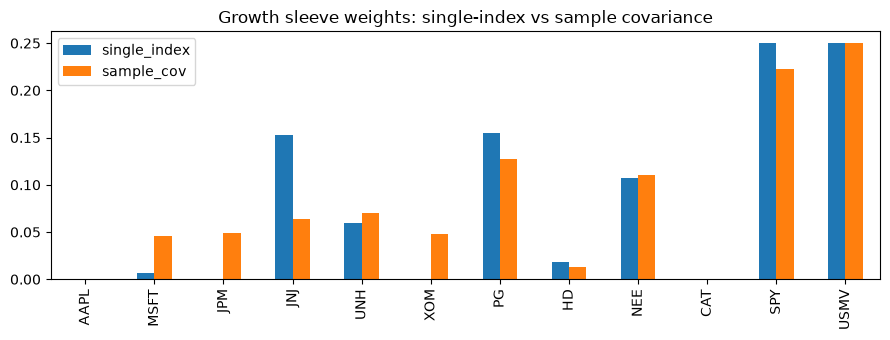

,eta_full_window,eta_last60m,recommended
AAPL,0.0000,0.0166,0.0000
MSFT,0.2752,0.2547,0.0067
JPM,0.0000,0.0000,0.0000
JNJ,0.0000,0.0000,0.1531
UNH,0.4091,0.2015,0.0600
XOM,0.0000,0.0530,0.0000
PG,0.0188,0.1866,0.1552
HD,0.0000,0.0000,0.0182
NEE,0.2968,0.2876,0.1069
CAT,0.0000,0.0000,0.0000


Rejected alt under common inputs: {'exp_return': 0.07607415991054937, 'vol': 0.1468802357597349, 'loss95_fund': 0.09012627824914006} | hist Sharpe: 1.515262683289317


In [8]:
mkt = Fw["Mkt-RF"]
beta = ex.apply(lambda s: s.cov(mkt)/mkt.var())
alpha_i = ex.mean() - beta*mkt.mean()
resid = ex - pd.DataFrame(np.outer(mkt, beta), index=ex.index, columns=ex.columns) - alpha_i
S_si = pd.DataFrame(np.outer(beta, beta)*mkt.var() + np.diag(resid.var()), index=ASSETS, columns=ASSETS)*12
S_sa = ex.cov()*12
mu = rf_ann + beta*P["ERP"]

def mv_opt(mu, S, A, maxw):
    n = len(mu); m = mu.values; Sv = S.values
    if n * maxw < 1:
        raise ValueError(f"Infeasible per-security cap {maxw} for {n} assets")
    r = minimize(lambda w: -(w@m - 0.5*A*w@Sv@w), np.ones(n)/n, jac=lambda w: -(m - A*Sv@w), bounds=[(0, maxw)]*n,
                 constraints=[{"type":"eq","fun":lambda w: w.sum()-1,"jac":lambda w: np.ones(n)}], method="SLSQP")
    if not r.success:
        raise RuntimeError(f"Mean-variance optimization failed: {r.message}")
    if not np.isclose(r.x.sum(), 1.0) or np.any(r.x < -1e-8) or np.any(r.x > maxw + 1e-8):
        raise RuntimeError("Mean-variance optimizer returned weights outside the mandate constraints")
    return pd.Series(r.x, index=mu.index)
def stats_p(w, S, mu):
    m = float(w@mu); s = float(np.sqrt(w@S@w)); return dict(exp_return=m, vol=s, loss95_fund=-(m-1.645*s)*share)
effN = lambda w: 1/(w**2).sum()

# (a) effect of risk aversion
rows = []
for A in [1, 2, 4, 6, 8, 12]:
    w = mv_opt(mu, S_si, A, P["MAX_W"]); rows.append(dict(A=A, **stats_p(w, S_si, mu), eff_N=effN(w), **{f"w_{t}": w[t] for t in ASSETS}))
save_table(pd.DataFrame(rows).set_index("A"), "T10_risk_aversion")

# (b) recommended: single-index risk, chosen A; same universe under sample covariance for comparison
A = P["RISK_AVERSION"]
w_rec = mv_opt(mu, S_si, A, P["MAX_W"]); w_sa = mv_opt(mu, S_sa, A, P["MAX_W"])
cmp_ = pd.DataFrame({"single_index": w_rec, "sample_cov": w_sa}); cmp_["diff"] = cmp_.single_index - cmp_.sample_cov
save_table(cmp_, "T11_weights_si_vs_sample")
cross = pd.DataFrame({"w_single_index": stats_p(w_rec, S_si, mu) | {"vol_under_sample": float(np.sqrt(w_rec@S_sa@w_rec))},
                      "w_sample_cov": stats_p(w_sa, S_sa, mu) | {"vol_under_sample": float(np.sqrt(w_sa@S_sa@w_sa))}})
cross.loc["vol_under_single_index"] = [float(np.sqrt(w_rec@S_si@w_rec)), float(np.sqrt(w_sa@S_si@w_sa))]
cross.loc["turnover_si_vs_sample"] = [0.5*(w_rec-w_sa).abs().sum()]*2
save_table(cross, "T12_risk_estimate_comparison")
cmp_[["single_index","sample_cov"]].plot.bar(figsize=(9,3.5), title="Growth sleeve weights: single-index vs sample covariance"); save_fig("F01_weights")

# (c) rejected alternative: Eta - highest historical Sharpe, sample covariance, long-only
def max_sharpe(exm):
    mu_h = exm.mean().values*12; Sh = exm.cov().values*12; n = len(mu_h)
    r = minimize(lambda w: -(w@mu_h)/np.sqrt(w@Sh@w), np.ones(n)/n, bounds=[(0,1)]*n,
                 constraints=[{"type":"eq","fun":lambda w: w.sum()-1}], method="SLSQP")
    if not r.success:
        raise RuntimeError(f"Historical Sharpe optimization failed: {r.message}")
    return pd.Series(r.x, index=exm.columns)
w_alt = max_sharpe(ex); w_alt60 = max_sharpe(ex.iloc[-60:])
alt = pd.DataFrame({"eta_full_window": w_alt, "eta_last60m": w_alt60, "recommended": w_rec})
alt.loc["effective_N"] = [effN(w_alt), effN(w_alt60), effN(w_rec)]
alt.loc["instability (half-L1 full vs 60m)"] = [0.5*(w_alt-w_alt60).abs().sum(), np.nan, np.nan]
save_table(alt, "T13_rejected_alternative")
print("Rejected alt under common inputs:", stats_p(w_alt, S_si, mu), "| hist Sharpe:", float((w_alt@ex.mean()*12)/np.sqrt(w_alt@S_sa@w_alt)))

In [9]:
# risk contributions, historical sleeve risk, trade-off checks
rp = Rw@w_rec; wealth = (1+rp).cumprod()
hist = pd.Series({"worst_12m_sleeve": ((1+rp).rolling(12).apply(np.prod, raw=True)-1).min(),
                  "max_drawdown_sleeve": (wealth/wealth.cummax()-1).min(),
                  "worst_12m_on_total_fund": ((1+rp).rolling(12).apply(np.prod, raw=True)-1).min()*share,
                  "model_loss95_on_total_fund": stats_p(w_rec, S_si, mu)["loss95_fund"],
                  "expected_return_sleeve": stats_p(w_rec, S_si, mu)["exp_return"],
                  "required_return_base_inflation": req_ret(P["INFLATION"])})
save_table(hist.to_frame("value"), "T14_recommended_checks")
print("Loss diagnostic below threshold:", hist["model_loss95_on_total_fund"] <= P["LOSS_LIMIT"], "| expected return >= required:", hist["expected_return_sleeve"] >= hist["required_return_base_inflation"])
rc = w_rec*(S_si@w_rec)/(w_rec@S_si@w_rec)
save_table(pd.DataFrame({"weight": w_rec, "risk_contribution": rc, "beta": beta}), "T15_risk_contributions")

# sensitivity: ERP and cap
rows = {}
for e in [0.03, 0.04, 0.05, 0.06, 0.07]: rows[f"ERP={e:.0%}"] = mv_opt(rf_ann+beta*e, S_si, A, P["MAX_W"])
for cap in [0.15, 0.35, 1.0]: rows[f"cap={cap:.0%}"] = mv_opt(mu, S_si, A, cap)
save_table(pd.DataFrame(rows), "T16_sensitivity")

# initial dollar allocation (full USD 12m)
alloc = pd.concat([hold["cost_usd"].rename("usd"), (w_rec*G_total).rename("usd")]) 
alloc.loc["Cash buffer"] = P["CASH_BUFFER"] - tc_initial; alloc.loc["Trading costs (growth buy)"] = tc_initial
alloc = alloc.to_frame(); alloc["pct_of_fund"] = alloc.usd/P["FUND"]
assert abs(alloc.usd.sum() - P["FUND"]) < 1, alloc.usd.sum()
save_table(alloc, "T17_initial_allocation")

,value
worst_12m_sleeve,-0.0742
max_drawdown_sleeve,-0.1606
worst_12m_on_total_fund,-0.0404
model_loss95_on_total_fund,0.0623
expected_return_sleeve,0.0759
required_return_base_inflation,0.0480


Loss diagnostic below threshold: True | expected return >= required: True


,weight,risk_contribution,beta
AAPL,0.0000,0.0000,1.2083
MSFT,0.0067,0.0087,0.9598
JPM,0.0000,0.0000,1.1462
JNJ,0.1531,0.1372,0.5252
UNH,0.0600,0.0618,0.6697
XOM,0.0000,0.0000,1.0228
PG,0.1552,0.1153,0.3681
HD,0.0182,0.0227,0.9105
NEE,0.1069,0.0827,0.3919
CAT,0.0000,0.0000,1.1361


,ERP=3%,ERP=4%,ERP=5%,ERP=6%,ERP=7%,cap=15%,cap=35%,cap=100%
AAPL,0.0000,0.0000,0.0000,0.0000,0.0094,0.0000,0.0000,0.0000
MSFT,0.0021,0.0012,0.0067,0.0277,0.0383,0.0540,0.0049,0.0000
JPM,0.0000,0.0000,0.0000,0.0019,0.0196,0.0115,0.0000,0.0000
JNJ,0.2060,0.1788,0.1531,0.1428,0.1209,0.1500,0.1404,0.1302
UNH,0.0803,0.0680,0.0600,0.0598,0.0564,0.1000,0.0542,0.0519
XOM,0.0000,0.0000,0.0000,0.0082,0.0157,0.0159,0.0000,0.0000
PG,0.2202,0.1878,0.1552,0.1328,0.1079,0.1500,0.1429,0.1400
HD,0.0186,0.0154,0.0182,0.0372,0.0457,0.0688,0.0127,0.0152
NEE,0.1459,0.1251,0.1069,0.0896,0.0751,0.1442,0.0993,0.0913
CAT,0.0000,0.0000,0.0000,0.0000,0.0110,0.0056,0.0000,0.0000


,usd,pct_of_fund
Alpha,-0.000000e+00,-0.0000
Beta,2.004278e+06,0.1670
Gamma,-0.000000e+00,-0.0000
Delta,3.212616e+06,0.2677
AAPL,0.000000e+00,0.0000
MSFT,4.372583e+04,0.0036
JPM,0.000000e+00,0.0000
JNJ,1.000150e+06,0.0833
UNH,3.921705e+05,0.0327
XOM,0.000000e+00,0.0000


,usd,pct_of_fund
Alpha,-0.000000e+00,-0.000000e+00
Beta,2.004278e+06,1.670232e-01
Gamma,-0.000000e+00,-0.000000e+00
Delta,3.212616e+06,2.677180e-01
AAPL,0.000000e+00,0.000000e+00
MSFT,4.372583e+04,3.643819e-03
JPM,4.638148e-11,3.865123e-18
JNJ,1.000150e+06,8.334580e-02
UNH,3.921705e+05,3.268087e-02
XOM,0.000000e+00,0.000000e+00


## 5. Market vs multifactor explanations
Compare the market-only CAPM (Mkt-RF), FF3 (Mkt-RF, SMB, HML), and FF5 (Mkt-RF, SMB, HML, RMW, CMA) for the growth portfolio and selected securities. HAC standard errors use 3 lags.
Alpha is the monthly intercept multiplied by 12 for an annualized simple rate; the reported alpha t-statistic is the original, unannualized HAC t-statistic. An in-sample intercept is average return unexplained by these factors; it does **not** show skill and may reflect estimation error or omitted factors. In this sample the growth portfolio's FF3 market beta is 0.715 (t=17.45), SMB beta −0.335 (t=−6.50), and HML beta 0.012 (t=0.29); FF5 estimates RMW 0.272 (t=3.58) and CMA 0.296 (t=4.06). Alpha falls from 5.02% annualized under CAPM to 4.18% under FF3 and 2.34% under FF5 (FF5 t=1.58), so the residual estimate is uncertain and should not drive the allocation. AAPL has positive market exposure and negative HML exposure; XOM has positive HML exposure. These are historical associations, not causal effects. Expected returns remain CAPM-anchored; factor regressions diagnose exposures and do not supply persistent alpha forecasts.

In [10]:
models = {"CAPM": ["Mkt-RF"], "FF3": FF3, "FF5": FF5}
expected_models = {
    "CAPM": ("Mkt-RF",),
    "FF3": ("Mkt-RF", "SMB", "HML"),
    "FF5": ("Mkt-RF", "SMB", "HML", "RMW", "CMA"),
}
if {name: tuple(cols) for name, cols in models.items()} != expected_models:
    raise ValueError("Factor regression specifications do not match CAPM, FF3, and FF5")
expected_regression_index = pd.period_range(W0, W1, freq="M")
def run_reg(y, cols):
    if not Fw.index.equals(expected_regression_index) or not y.index.equals(expected_regression_index):
        raise ValueError("Regression dates must exactly match the frozen 96-month 2015-01 to 2022-12 estimation window")
    if len(y) != 96:
        raise ValueError(f"Frozen factor regression requires 96 monthly observations; found {len(y)}")
    if not set(cols).issubset(Fw.columns):
        raise ValueError(f"Regression is missing required factors: {set(cols) - set(Fw.columns)}")
    if not np.isfinite(y.to_numpy()).all() or not np.isfinite(Fw[cols].to_numpy()).all():
        raise ValueError("Regression contains missing or non-finite return/factor observations")
    r = sm.OLS(y, sm.add_constant(Fw[cols])).fit(cov_type="HAC", cov_kwds={"maxlags": 3})
    row = {"alpha_ann": r.params["const"]*12, "alpha_t": r.tvalues["const"],
           "R2": r.rsquared, "adjR2": r.rsquared_adj, "nobs": int(r.nobs),
           "sample_start": str(y.index.min()), "sample_end": str(y.index.max()),
           "frequency": "monthly", "factor_columns": ", ".join(cols)}
    for c in cols:
        row[f"b_{c}"] = r.params[c]
        row[f"t_{c}"] = r.tvalues[c]
    return row, r
if not np.isclose(w_rec.sum(), 1.0, atol=1e-10):
    raise ValueError("Frozen growth sleeve must be fully invested before subtracting RF once")
ex_g = (Rw@w_rec) - Fw["RF"]
items = {"Growth portfolio": ex_g, **{s: ex[s] for s in P["FACTOR_STOCKS"]}}
rows, fits = [], {}
for nm, y in items.items():
    for mn, cols in models.items():
        row, r = run_reg(y, cols)
        fits[(nm, mn)] = r
        rows.append(dict(asset=nm, model=mn, **row))
save_table(pd.DataFrame(rows).set_index(["asset", "model"]), "T18_factor_regressions")

prem = pd.DataFrame({"premium_ann": Fw[FF5].mean()*12, "t_stat": Fw[FF5].mean()/(Fw[FF5].std()/np.sqrt(len(Fw)))})
save_table(prem, "T19_factor_premia_window")
rows = []
for nm in items:
    r3 = fits[(nm, "FF3")]
    r5 = fits[(nm, "FF5")]
    capm = fits[(nm, "CAPM")]
    rows.append(dict(asset=nm, capm_exp_ret=rf_ann+capm.params["Mkt-RF"]*P["ERP"],
                     ff3_exp_ret_hist_premia=rf_ann+sum(r3.params[c]*prem.loc[c, "premium_ann"] for c in FF3),
                     ff5_exp_ret_hist_premia=rf_ann+sum(r5.params[c]*prem.loc[c, "premium_ann"] for c in FF5),
                     ff3_exp_ret_mkt_at_ERP=rf_ann+r3.params["Mkt-RF"]*P["ERP"],
                     ff5_exp_ret_mkt_at_ERP=rf_ann+r5.params["Mkt-RF"]*P["ERP"]))
save_table(pd.DataFrame(rows).set_index("asset"), "T20_expected_returns_by_model")

# Evaluation observations are reserved for this post-estimation check, not model or strategy selection.
ev = ret_tr.loc[E0:E1]
Fe = fac.loc[E0:E1]
idx = ev.index.intersection(Fe.index)
expected_eval = pd.period_range(E0, E1, freq="M")
if not idx.equals(expected_eval) or not ev.index.equals(expected_eval) or not Fe.index.equals(expected_eval):
    raise ValueError("Evaluation returns and factors must exactly match the frozen 2023-01 to 2025-12 window")
rows = []
for nm in items:
    y = ((ev.loc[idx]@w_rec) if nm == "Growth portfolio" else ev.loc[idx, nm]) - Fe.loc[idx, "RF"]
    r = fits[(nm, "FF5")]
    fitted = sum(r.params[c]*Fe.loc[idx, c] for c in FF5)
    e = y - fitted
    if not np.isfinite(e.to_numpy()).all():
        raise ValueError(f"Non-finite out-of-sample regression residuals for {nm}")
    oos_fit = sm.OLS(e, np.ones((len(e), 1))).fit(cov_type="HAC", cov_kwds={"maxlags": 3})
    rows.append(dict(asset=nm, months=len(idx), oos_alpha_ann=e.mean()*12,
                     t_stat_hac=float(np.asarray(oos_fit.tvalues).reshape(-1)[0]), t_stat_method="HAC, 3 lags",
                     in_sample_alpha_ann=r.params["const"]*12))
save_table(pd.DataFrame(rows).set_index("asset"), "T21_oos_alpha_check")

alpha_ann  alpha_t      R2   adjR2  nobs sample_start  \
asset            model                                                          
Growth portfolio CAPM      0.0502   2.7145  0.7685  0.7661    96      2015-01   
                 FF3       0.0418   2.6219  0.8279  0.8223    96      2015-01   
                 FF5       0.0234   1.5764  0.8691  0.8618    96      2015-01   
AAPL             CAPM      0.1212   1.7337  0.4683  0.4626    96      2015-01   
                 FF3       0.1084   1.6982  0.5411  0.5261    96      2015-01   
                 FF5       0.0950   1.4861  0.5521  0.5272    96      2015-01   
XOM              CAPM     -0.0014  -0.0125  0.3398  0.3328    96      2015-01   
                 FF3       0.0163   0.2338  0.6121  0.5995    96      2015-01   
                 FF5       0.0074   0.1012  0.6434  0.6236    96      2015-01   

                       sample_end frequency              factor_columns  \
asset            model                                                    
Growth portfolio CAPM     2022-12   monthly                      Mkt-RF   
                 FF3      2022-12   monthly            Mkt-RF, SMB, HML   
                 FF5      2022-12   monthly  Mkt-RF, SMB, HML, RMW, CMA   
AAPL             CAPM     2022-12   monthly                      Mkt-RF   
                 FF3      2022-12   monthly            Mkt-RF, SMB, HML   
                 FF5      2022-12   monthly  Mkt-RF, SMB, HML, RMW, CMA   
XOM              CAPM     2022-12   monthly                      Mkt-RF   
                 FF3      2022-12   monthly            Mkt-RF, SMB, HML   
                 FF5      2022-12   monthly  Mkt-RF, SMB, HML, RMW, CMA   

                        b_Mkt-RF  t_Mkt-RF   b_SMB   t_SMB   b_HML   t_HML  \
asset            model                                                       
Growth portfolio CAPM     0.6572   18.6824     NaN     NaN     NaN     NaN   
                 FF3      0.7151   17.4499 -0.3348 -6.5044  0.0125  0.2885   
                 FF5      0.7156   18.2068 -0.2018 -2.9884 -0.1595 -2.4213   
AAPL             CAPM     1.2083   10.5335     NaN     NaN     NaN     NaN   
                 FF3      1.2824   11.1714 -0.3480 -1.5903 -0.4757 -2.9191   
                 FF5      1.2169    9.6100 -0.1752 -0.7465 -0.5151 -2.3822   
XOM              CAPM     1.0228    4.6727     NaN     NaN     NaN     NaN   
                 FF3      0.9314    8.7836  0.3542  1.4516  1.0411  4.0730   
                 FF5      1.0606    8.7303  0.2697  1.0067  0.7898  2.6253   

                         b_RMW   t_RMW   b_CMA   t_CMA  
asset            model                                  
Growth portfolio CAPM      NaN     NaN     NaN     NaN  
                 FF3       NaN     NaN     NaN     NaN  
                 FF5    0.2722  3.5754  0.2961  4.0649  
AAPL             CAPM      NaN     NaN     NaN     NaN  
                 FF3       NaN     NaN     NaN     NaN  
                 FF5    0.4786  1.5224 -0.0979 -0.2831  
XOM              CAPM      NaN     NaN     NaN     NaN  
                 FF3       NaN     NaN     NaN     NaN  
                 FF5   -0.4178 -1.2986  0.7576  1.8941

,premium_ann,t_stat
Mkt-RF,0.0997,1.7075
SMB,-0.0080,-0.2365
HML,-0.0055,-0.1172
RMW,0.0478,1.8475
CMA,0.0184,0.6291


,capm_exp_ret,ff3_exp_ret_hist_premia,ff5_exp_ret_hist_premia,ff3_exp_ret_mkt_at_ERP,ff5_exp_ret_mkt_at_ERP
asset,,,,,
Growth portfolio,0.0759,0.1169,0.1353,0.0788,0.0788
AAPL,0.1034,0.1763,0.1896,0.1071,0.1038
XOM,0.0941,0.1273,0.1362,0.0896,0.0960


,months,oos_alpha_ann,t_stat_hac,t_stat_method,in_sample_alpha_ann
asset,,,,,
Growth portfolio,36,-0.0537,-1.2464,"HAC, 3 lags",0.0234
AAPL,36,-0.0156,-0.1274,"HAC, 3 lags",0.0950
XOM,36,-0.0264,-0.2322,"HAC, 3 lags",0.0074


,months,oos_alpha_ann,t_stat_hac,t_stat_method,in_sample_alpha_ann
asset,,,,,
Growth portfolio,36,-0.053662,-1.246412,"HAC, 3 lags",0.023446
AAPL,36,-0.015626,-0.127424,"HAC, 3 lags",0.094989
XOM,36,-0.026380,-0.232157,"HAC, 3 lags",0.007391


## 6. Evidence against the recommendation: frozen strategy vs frozen benchmark, 2023–2025
Weights frozen at 31 Dec 2022; rebalance at December month-end only when any absolute weight drift exceeds 5 percentage points; 10bp one-way cost on turnover, including initial purchase. Benchmark = SPY, same costs. No decision above uses these data. T22 reports the number of triggered rebalances.

,cumulative,ann_return,ann_vol,sharpe,max_drawdown,worst_12m,tracking_error_vs_bench,active_return_ann_vs_bench,rebalance_count
Recommended (frozen),0.3545,0.1064,0.1058,0.5664,-0.0718,0.0339,0.0855,-0.1072,1
Benchmark SPY,0.8531,0.2283,0.1194,1.3998,-0.0833,0.0830,NaN,NaN,0
Rejected: Eta max-Sharpe,0.1538,0.0488,0.1553,0.0804,-0.2132,-0.1565,0.1521,-0.1547,2
Sample-cov MV,0.4092,0.1211,0.1015,0.7174,-0.0738,0.0407,0.0757,-0.0944,1


,Recommended (frozen),Benchmark SPY,Rejected: Eta max-Sharpe,Sample-cov MV
date,,,,
2023-01,-0.0157,0.0618,-0.0486,-0.0040
2023-02,-0.0371,-0.0251,-0.0285,-0.0312
2023-03,0.0419,0.0371,0.0718,0.0388
2023-04,0.0274,0.0160,0.0367,0.0310
2023-05,-0.0317,0.0046,0.0097,-0.0289
2023-06,0.0508,0.0648,0.0137,0.0481
2023-07,0.0229,0.0327,0.0115,0.0236
2023-08,-0.0229,-0.0163,-0.0505,-0.0234
2023-09,-0.0451,-0.0474,-0.0261,-0.0374


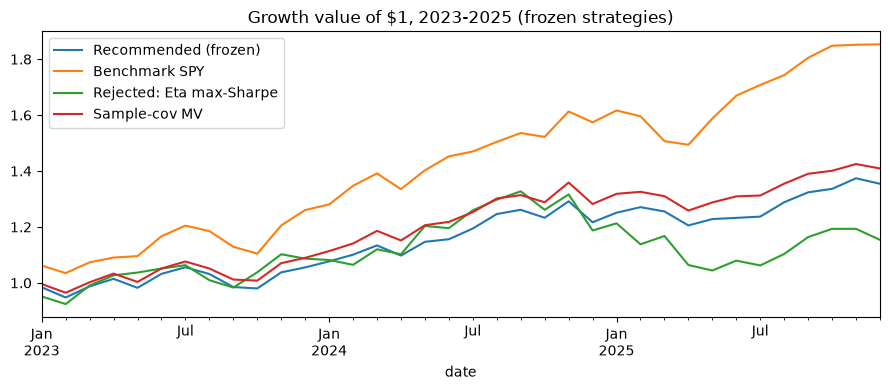

Worst 12m of recommended sleeve x share of fund: 0.018438674875276964
Rebalance rule: December only when max absolute weight drift > 5%
NOTE: 3 years of results do not show that the 8-year goal is achieved.


In [11]:
Re = ret_tr.loc[E0:E1, ASSETS]
if Re.isna().any().any() or not np.isfinite(Re.to_numpy()).all():
    raise ValueError("Evaluation return panel contains missing or non-finite observations")
REBALANCE_DRIFT = 0.05
def run_strategy(w, R, tc, drift_limit=REBALANCE_DRIFT):
    w = w.reindex(R.columns).fillna(0).to_numpy(dtype=float)
    if not np.isclose(w.sum(), 1.0, atol=1e-10) or np.any(w < -1e-10):
        raise ValueError("Backtest strategy weights must be nonnegative and sum to one")
    if not 0 <= tc < 1 or not 0 <= drift_limit < 1:
        raise ValueError("Transaction cost or rebalance drift threshold is outside its valid range")
    pos = w*(1-tc); prev = 1.0; out = []; rebalance_count = 0
    for d, row in zip(R.index, R.to_numpy()):
        pos = pos*(1+row); v = pos.sum()
        if v <= 0 or not np.isfinite(v):
            raise ValueError(f"Invalid portfolio value during evaluation at {d}")
        drift = np.max(np.abs(pos/v-w))
        if d.month == 12 and drift > drift_limit:
            cost = tc*np.abs(w*v-pos).sum()
            v -= cost
            pos = w*v
            rebalance_count += 1
        out.append(v/prev-1); prev = v
    return pd.Series(out, index=R.index), rebalance_count
def perf(r, rf):
    n = len(r); cum = (1+r).prod()-1; vol = r.std()*np.sqrt(12); e = (r-rf.reindex(r.index)).dropna(); wl = (1+r).cumprod()
    return dict(cumulative=cum, ann_return=(1+cum)**(12/n)-1, ann_vol=vol, sharpe=e.mean()*12/vol,
                max_drawdown=(wl/wl.cummax()-1).min(), worst_12m=((1+r).rolling(12).apply(np.prod, raw=True)-1).min())
bench_w = pd.Series({P["BENCH"]: 1.0})
strats = {"Recommended (frozen)": w_rec, "Benchmark SPY": bench_w, "Rejected: Eta max-Sharpe": w_alt, "Sample-cov MV": w_sa}
strategy_results = {k: run_strategy(w, Re, P["TC"]) for k, w in strats.items()}
rets = {k: result[0] for k, result in strategy_results.items()}
tab = pd.DataFrame({k: perf(r, fac["RF"]) for k, r in rets.items()}).T
act = rets["Recommended (frozen)"] - rets["Benchmark SPY"]
tab["tracking_error_vs_bench"] = [np.nan if k == "Benchmark SPY" else (rets[k]-rets["Benchmark SPY"]).std()*np.sqrt(12) for k in tab.index]
tab["active_return_ann_vs_bench"] = [np.nan if k == "Benchmark SPY" else (rets[k]-rets["Benchmark SPY"]).mean()*12 for k in tab.index]
tab["rebalance_count"] = [strategy_results[k][1] for k in tab.index]
save_table(tab, "T22_evaluation_2023_2025")
evaluation_returns = pd.DataFrame(rets, index=Re.index)
evaluation_returns.index.name = "date"
if not evaluation_returns.index.equals(pd.period_range(E0, E1, freq="M")):
    raise ValueError("Monthly evaluation outputs do not match the frozen 2023-01 to 2025-12 window")
save_table(evaluation_returns, "T25_evaluation_monthly_returns")
pd.DataFrame({k: (1+r).cumprod() for k, r in rets.items()}).set_index(Re.index.to_timestamp()).plot(figsize=(9,4), title="Growth value of $1, 2023-2025 (frozen strategies)")
save_fig("F02_evaluation")
print("Worst 12m of recommended sleeve x share of fund:", tab.loc["Recommended (frozen)","worst_12m"]*share)
print("Rebalance rule:", f"December only when max absolute weight drift > {REBALANCE_DRIFT:.0%}")
print("NOTE: 3 years of results do not show that the 8-year goal is achieved.")

## 7. What would change the recommendation: thresholds and goal probability
Decision tested: *is the growth sleeve expected to reach the real goal?* Reversal thresholds: ERP below which expected return < required return; inflation above which the goal is out of reach in expectation. Probability uses a lognormal sleeve value with constant weights (costs and rebalancing ignored), so it is a planning approximation, not a guarantee or full transaction-cost simulation. At the base assumptions, T23's probability is below 75%; the P25 real-value estimate is below the USD 8m goal. The thresholds identify when the expected-return/goal conclusion changes, not when the funded payment plan changes.

In [12]:
beta_p = float(w_rec@beta); sig_p = float(np.sqrt(w_rec@S_si@w_rec)); T = P["GOAL_YEARS"]
erp_star = (req_ret(P["INFLATION"]) - rf_ann)/beta_p
infl_star = brentq(lambda i: req_ret(i) - (rf_ann + beta_p*P["ERP"]), 0.0, 0.25)
print("Threshold ERP (at base inflation): %.2f%% | threshold inflation (at base ERP): %.2f%%" % (erp_star*100, infl_star*100))
thresholds = pd.DataFrame([{"base_inflation": P["INFLATION"], "erp_threshold": erp_star, "base_erp": P["ERP"], "inflation_threshold": infl_star, "required_growth_return": req_ret(P["INFLATION"]), "expected_growth_return": rf_ann + beta_p*P["ERP"]}], index=["expected-growth-goal crossover"])
save_table(thresholds, "T26_reversal_thresholds")
def logn(mu_p):
    s2 = np.log(1+sig_p**2/(1+mu_p)**2); return np.log(1+mu_p) - s2/2, s2
def p_goal(erp, infl):
    mL, s2 = logn(rf_ann + beta_p*erp)
    return 1 - norm.cdf((np.log(need_growth(infl)/G_total) - mL*T)/np.sqrt(s2*T))
grid = pd.DataFrame({f"infl={i:.1%}": [p_goal(e, i) for e in [0.03,0.04,0.05,0.06]] for i in [0.02,0.025,0.03,0.04]},
                    index=[f"ERP={e:.0%}" for e in [0.03,0.04,0.05,0.06]])
save_table(grid, "T23_goal_probability")
mL, s2 = logn(rf_ann + beta_p*P["ERP"]); q = lambda z: G_total*np.exp(mL*T + z*np.sqrt(s2*T))
real = lambda g: (g + other)/(1+P["INFLATION"])**T
pct = pd.DataFrame({"real_fund_value_dec2022_usd": [real(q(norm.ppf(p))) for p in [0.10, 0.25, 0.50]]}, index=["P10","P25","P50"])
save_table(pct, "T24_real_value_distribution")
print("Real goal supported with ~75%% probability: USD %.2fm (vs 8.00m target)" % (real(q(norm.ppf(0.25)))/1e6))

Threshold ERP (at base inflation): 0.75% | threshold inflation (at base ERP): 5.17%


,base_inflation,erp_threshold,base_erp,inflation_threshold,required_growth_return,expected_growth_return
expected-growth-goal crossover,0.025,0.0075,0.05,0.0517,0.048,0.0759


,infl=2.0%,infl=2.5%,infl=3.0%,infl=4.0%
ERP=3%,0.6337,0.5835,0.5322,0.4298
ERP=4%,0.6940,0.6464,0.5967,0.4942
ERP=5%,0.7498,0.7059,0.6590,0.5592
ERP=6%,0.7999,0.7606,0.7176,0.6230


,real_fund_value_dec2022_usd
P10,6.431516e+06
P25,7.691355e+06
P50,9.391980e+06


Real goal supported with ~75% probability: USD 7.69m (vs 8.00m target)


## 8. Freeze the policy (22 Oct record) and list outputs
Monitoring items for the memo: realised vs plan funding cash flows; rate level and curve shape vs scenarios; growth sleeve drawdown and the loss diagnostic; inflation vs 2.5%; ERP/valuation; factor-exposure drift; rebalance trigger (at December month-end, if any target-weight drift exceeds 5pp). The 2.5% inflation, 5% ERP, risk aversion 4, 15% total-fund loss interpretation, 25% cap, and 10bp trading cost are team judgments; the PDF leaves these unspecified.

In [13]:
frozen = {"params": {k: (v if not isinstance(v, dict) else {str(a): b for a, b in v.items()}) for k, v in P.items()},
          "bond_units": hold["units"].to_dict(), "growth_weights": w_rec.round(6).to_dict(), "growth_usd": float(G_total),
          "cash_buffer_net": float(P["CASH_BUFFER"]-tc_initial), "rebalance_rule": "each December to frozen weights; trade if drift > 5pp",
          "benchmark": P["BENCH"], "estimation_window": list(P["WIN"]), "evaluation_window": list(P["EVAL"])}
policy_path = OUT/"frozen_policy.json"
frozen = json.loads(json.dumps(frozen, default=float))
if policy_path.exists():
    saved_policy = json.loads(policy_path.read_text(encoding="utf-8"))
    if saved_policy != frozen:
        raise ValueError(f"Refusing to overwrite frozen policy at {policy_path}; set TAG to a new revision and compare against outputs/original")
else:
    policy_path.write_text(json.dumps(frozen, indent=2), encoding="utf-8")
print(sorted(p.name for p in OUT.iterdir()))

['F01_weights.png', 'F02_evaluation.png', 'T00_source_record.csv', 'T01_data_quality.csv', 'T02_universe.csv', 'T03_spot_curve.csv', 'T04_bond_analytics.csv', 'T05_duration_vs_exact.csv', 'T06_funding_cashflows.csv', 'T07_bond_holdings.csv', 'T08_rate_scenarios_funding.csv', 'T09_goal_requirements.csv', 'T10_risk_aversion.csv', 'T11_weights_si_vs_sample.csv', 'T12_risk_estimate_comparison.csv', 'T13_rejected_alternative.csv', 'T14_recommended_checks.csv', 'T15_risk_contributions.csv', 'T16_sensitivity.csv', 'T17_initial_allocation.csv', 'T18_factor_regressions.csv', 'T19_factor_premia_window.csv', 'T20_expected_returns_by_model.csv', 'T21_oos_alpha_check.csv', 'T22_evaluation_2023_2025.csv', 'T23_goal_probability.csv', 'T24_real_value_distribution.csv', 'T25_evaluation_monthly_returns.csv', 'T26_reversal_thresholds.csv', 'frozen_policy.json']


## Audit validation and reproducibility checks
Execute only after the notebook has built the required outputs. This validates the key assumptions, raw-data provenance, bond repricing checks, and the final policy snapshot against the case requirements.


In [14]:
# Audit assertions for the final submission
from pathlib import Path
import json
import pandas as pd

RAW = ROOT / "data" / "raw"
OUT = ROOT / "outputs" / "original"
assert (RAW / "source_record.json").exists(), "Missing raw source record"
source = json.loads((RAW / "source_record.json").read_text(encoding="utf-8"))
assert source["failures"] == [], "Raw retrieval failures remain"
assert len({e["id"] for e in source["entries"]}) >= 12, "Fewer than 12 raw data series were retrieved"
import hashlib
for entry in source["entries"]:
    source_file = ROOT / entry["file"]
    assert source_file.is_file(), f"Missing recorded raw source file: {source_file}"
    assert hashlib.sha256(source_file.read_bytes()).hexdigest() == entry["sha256"], f"Raw source hash mismatch: {source_file}"
assert (OUT / "frozen_policy.json").exists(), "Final policy snapshot missing"
policy = json.loads((OUT / "frozen_policy.json").read_text(encoding="utf-8"))
assert policy["params"]["FUND"] == 12_000_000
assert policy["params"]["GOAL_REAL"] == 8_000_000
assert policy["params"]["GOAL_YEARS"] == 8
assert abs(policy["params"]["INFLATION"] - 0.025) < 1e-12
assert (OUT / "T05_duration_vs_exact.csv").exists() and (OUT / "T09_goal_requirements.csv").exists()
dur = pd.read_csv(OUT / "T05_duration_vs_exact.csv")
assert dur["error_dur_conv"].abs().max() < 0.01, "Bond repricing error exceeds tolerance"
backtest = pd.read_csv(OUT / "T22_evaluation_2023_2025.csv")
assert set(backtest.columns) >= {"ann_return", "ann_vol", "sharpe"}, "Backtest summary columns missing"
assert backtest.loc[backtest["cumulative"].idxmax(), "cumulative"] > 0, "Benchmark/backtest summary invalid"
reg = pd.read_csv(OUT / "T18_factor_regressions.csv")
expected_factor_sets = {"CAPM": "Mkt-RF", "FF3": "Mkt-RF, SMB, HML", "FF5": "Mkt-RF, SMB, HML, RMW, CMA"}
assert set(reg["model"]) == set(expected_factor_sets) and len(reg) == 9, "Regression models or asset coverage are incorrect"
for model, factors in expected_factor_sets.items():
    subset = reg.loc[reg["model"] == model]
    assert len(subset) == 3 and subset["factor_columns"].eq(factors).all(), f"Incorrect factor columns for {model}"
assert reg["nobs"].eq(96).all() and reg["sample_start"].eq("2015-01").all() and reg["sample_end"].eq("2022-12").all() and reg["frequency"].eq("monthly").all(), "Regression window does not match the frozen policy"
oos = pd.read_csv(OUT / "T21_oos_alpha_check.csv")
assert {"t_stat_hac", "t_stat_method"}.issubset(oos.columns) and oos["t_stat_method"].eq("HAC, 3 lags").all(), "OOS alpha t-statistics must use unannualized HAC inference"
backtest = pd.read_csv(OUT / "T22_evaluation_2023_2025.csv", index_col=0)
assert "rebalance_count" in backtest.columns and backtest.loc["Recommended (frozen)", "rebalance_count"] == 1 and backtest.loc["Benchmark SPY", "rebalance_count"] == 0, "Evaluation does not reflect the December-only 5pp rebalance trigger"
assert abs(sum(policy["growth_weights"].values()) - 1.0) < 1e-5, "Frozen growth allocation no longer sums to one"
print("Audit assertions passed: provenance hashes, frozen monthly window, CAPM/FF3/FF5, HAC evaluation, conditional rebalancing, and unchanged allocation.")


Audit assertions passed: provenance hashes, frozen monthly window, CAPM/FF3/FF5, HAC evaluation, conditional rebalancing, and unchanged allocation.
